# 02 — Exploring the Data (EDA)

Charts and numbers describing the cleaned TRAINING data, and a short report
saved to `reports/eda_report.md`. We only look at the train file here — the
test file is kept aside for later so we don't accidentally peek at it.

In [10]:
import os
import pandas as pd
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
os.makedirs("reports/figures", exist_ok=True)

train = pd.read_parquet("data/processed/train.parquet")
print("Training rows:", len(train))

Training rows: 47121


product
Credit card or prepaid card                                                     8000
Debt collection                                                                 8000
Checking or savings account                                                     8000
Credit reporting, credit repair services, or other personal consumer reports    8000
Mortgage                                                                        5736
Money transfer, virtual currency, or money service                              3254
Vehicle loan or lease                                                           3156
Payday loan, title loan, or personal loan                                       1663
Student loan                                                                    1312
Name: count, dtype: int64


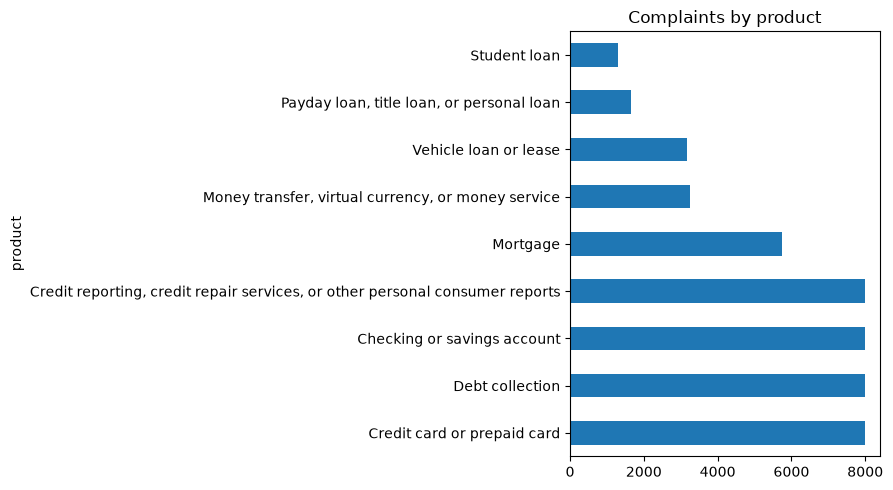

In [11]:
# Complaints by product type (very unbalanced — one category dominates).
product_counts = train["product"].value_counts()
print(product_counts)

product_counts.plot(kind="barh", figsize=(9, 5), title="Complaints by product")
plt.tight_layout()
plt.savefig("reports/figures/product_distribution.png")
plt.show()

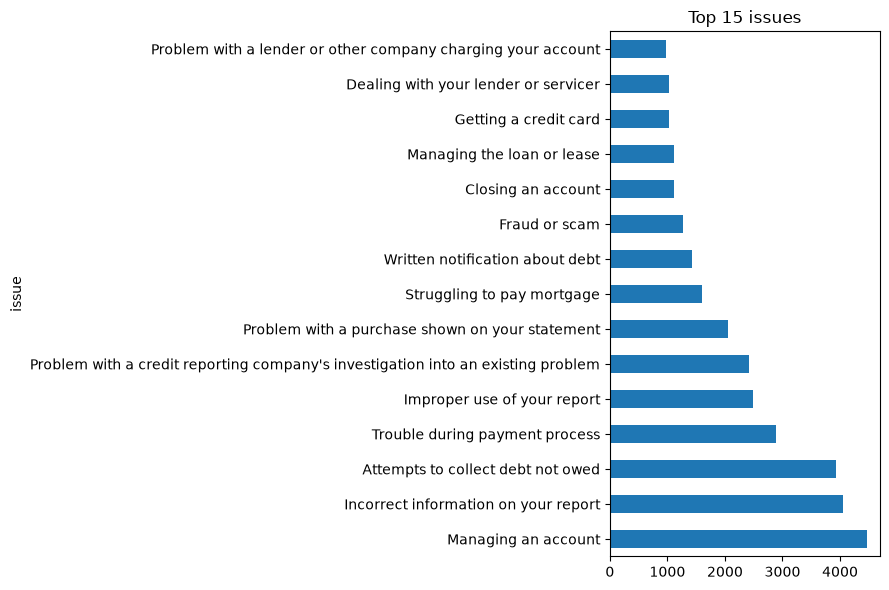

In [12]:
# Top 15 issue types.
issue_counts = train["issue"].value_counts().head(15)
issue_counts.plot(kind="barh", figsize=(9, 6), title="Top 15 issues")
plt.tight_layout()
plt.savefig("reports/figures/issue_distribution.png")
plt.show()

Typical length: 149 words
95% are under: 619 words


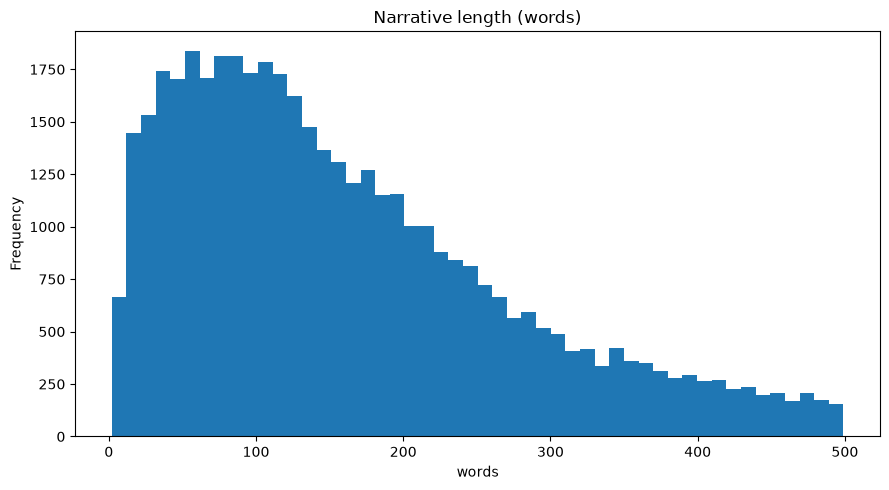

In [13]:
# How long are the narratives, in words?
train["word_count"] = train["consumer_complaint_narrative"].str.split().str.len()
median_words = int(train["word_count"].median())
p95_words = int(train["word_count"].quantile(0.95))
print("Typical length:", median_words, "words")
print("95% are under:", p95_words, "words")

# Plot only narratives under 500 words so a few very long ones don't squish the chart.
short = train[train["word_count"] < 500]
short["word_count"].plot(kind="hist", bins=50, figsize=(9, 5), title="Narrative length (words)")
plt.xlabel("words")
plt.tight_layout()
plt.savefig("reports/figures/narrative_length.png")
plt.show()

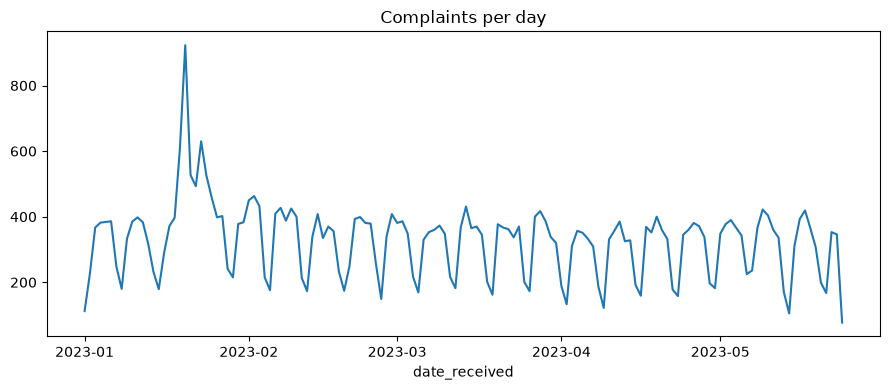

In [14]:
# Complaints per day.
train["date_received"] = pd.to_datetime(train["date_received"])
per_day = train.groupby(train["date_received"].dt.date).size()
per_day.plot(figsize=(9, 4), title="Complaints per day")
plt.tight_layout()
plt.savefig("reports/figures/temporal_volume.png")
plt.show()

Top 10 companies = 44.4 % of complaints


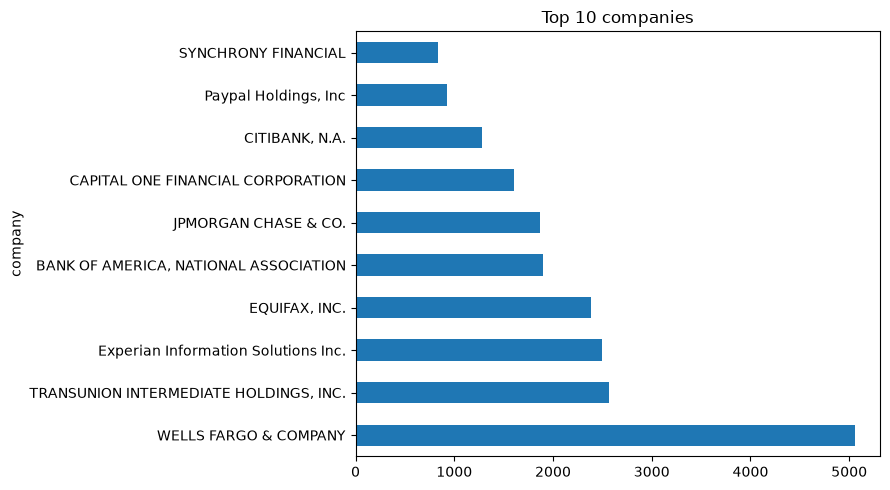

In [15]:
# Top 10 companies by complaint count.
top_companies = train["company"].value_counts().head(10)
top10_share = round(top_companies.sum() / len(train) * 100, 1)
print("Top 10 companies =", top10_share, "% of complaints")

top_companies.plot(kind="barh", figsize=(9, 5), title="Top 10 companies")
plt.tight_layout()
plt.savefig("reports/figures/company_concentration.png")
plt.show()

is_escalated
0    43097
1     4024
Name: count, dtype: int64
Escalation rate: 8.54 %


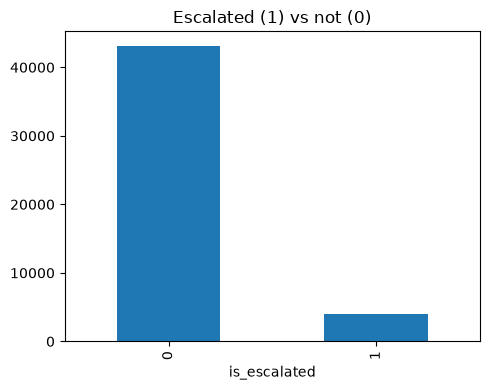

In [16]:
# How many complaints are "escalated"? (about 4% — very few)
escalation_rate = round(train["is_escalated"].mean() * 100, 2)
print(train["is_escalated"].value_counts())
print("Escalation rate:", escalation_rate, "%")

train["is_escalated"].value_counts().plot(kind="bar", figsize=(5, 4), title="Escalated (1) vs not (0)")
plt.tight_layout()
plt.savefig("reports/figures/class_balance.png")
plt.show()

In [17]:
# A couple of numbers from the RAW file: how many people opt in to a narrative,
# and how often personal info is blacked out as "XXXX".
raw = pd.read_csv("data/raw/cfpb_complaints_2023-03.csv", low_memory=False)
raw.columns = (raw.columns.str.lower()
               .str.replace("?", "", regex=False)
               .str.replace("-", "_", regex=False)
               .str.replace(" ", "_", regex=False))

opt_in = round(raw["consumer_complaint_narrative"].notna().mean() * 100, 1)
has_xxxx = round(train["consumer_complaint_narrative"].str.contains("XXXX").mean() * 100, 1)
print("Share of complaints with a narrative:", opt_in, "%")
print("Narratives containing XXXX:", has_xxxx, "%")

Share of complaints with a narrative: 36.9 %
Narratives containing XXXX: 82.5 %


In [18]:
# Write a short report with the main numbers and the charts.
top_product = product_counts.index[0]
top_product_share = round(product_counts.iloc[0] / len(train) * 100, 1)
approx_tokens = int(p95_words * 1.4)   # rough words -> tokens

report = f"""# EDA Report — CFPB Complaint Narratives

Based on the cleaned training data ({len(train)} complaints). The test set is
kept aside and not looked at here.

## Main points

- Only **{opt_in}%** of complaints have a written narrative (people opt in), so
  the data leans toward more motivated or frustrated customers.
- Biggest product category: **{top_product}** ({top_product_share}% of complaints).
  The categories are very unbalanced, so we report macro-averaged scores later.
- Escalation rate: **{escalation_rate}%** — very few, so the data is imbalanced and
  we care about PR-AUC and threshold tuning, not plain accuracy.
- Narrative length: about **{median_words}** words typically; 95% are under
  **{p95_words}** words (~{approx_tokens} tokens). Some are longer than BERT's
  512-token limit, so truncation is a real choice for the transformer.
- **{has_xxxx}%** of narratives contain "XXXX" (blacked-out personal info).
- The top 10 companies make up **{top10_share}%** of all complaints.

## Charts

![Products](figures/product_distribution.png)
![Issues](figures/issue_distribution.png)
![Narrative length](figures/narrative_length.png)
![Per day](figures/temporal_volume.png)
![Top companies](figures/company_concentration.png)
![Escalated](figures/class_balance.png)
"""

with open("reports/eda_report.md", "w") as f:
    f.write(report)
print("Wrote reports/eda_report.md")

Wrote reports/eda_report.md
